In [9]:
import numpy as np
import pandas as pd
from scipy.special import hankel2
from scipy import integrate

from mesh.load_meshes import load_meshes
from models import Nodes, Elements, Edges

nodes, elements = load_meshes()

### Physical parameters

In [10]:
E0 = 1  # Plane wave amplitude
EPS0: float = 8.85e-12  # Diel. permittivity of vacuum
EPS1: float = 1.0  # Permittivity of air
MU0: float = 4 * np.pi * 1e-7  # Mag. permeability of vacuum
MU1: float = 1.0  # Permeability of the air
SIG1 = 0.0  # Conductivity of the air (S/m)
V = 1 / np.sqrt(EPS0 * MU0 * EPS1 * MU1)  # wave speed
F_HZ = 4e9  # Plane wave frequency
OMEGA = 2 * np.pi * F_HZ  # Angular frequency
LAMBDA = V / F_HZ  # Wavelength
K0: float = 2 * np.pi / LAMBDA  # Free space wave number
KPW = np.array([0, K0])  # Direction of the plane wave

### Compute Boundary Elements 

In [11]:
def find_boundary_edges(elements: Elements) -> Edges:
    """Edges that belong to exactly one triangle: the outer border of the mesh."""
    tri = elements.node_idxs  # (T, 3)

    # Triangle [a, b, c] has edges (a,b), (b,c), (c,a), in that direction.
    edges = np.concatenate([tri[:, [0, 1]], tri[:, [1, 2]], tri[:, [2, 0]]])  # (3T, 2)

    # Two neighbours store their shared edge as (a,b) and (b,a).
    # Sorting each row makes both read (min, max), so they compare equal.
    sorted_edges = np.sort(edges, axis=1)

    # Count each distinct edge. `inverse` maps every row of `edges`
    # to its distinct edge, so counts[inverse] is a per-row count.
    # Interior edges appear twice, border edges once.
    _, inverse, counts = np.unique(
        sorted_edges, axis=0, return_inverse=True, return_counts=True
    )
    on_border = counts[inverse] == 1

    # Mask the UNSORTED edges, so the direction from the triangles survives.
    return Edges(node_idxs=edges[on_border])


boundary: Edges = find_boundary_edges(elements)  # air box + PEC slot edges

# Remove the air-box edges: their midpoint lies on one of the box's sides.
coords = nodes.xy[boundary.node_idxs]  # (M, 2 ends, 2 coords)
mid = coords.mean(axis=1)  # (M, 2)
box_min = nodes.xy.min(axis=0)  # (2,) = (x_min, y_min); taken from the mesh,
box_max = nodes.xy.max(axis=0)  # (2,) = (x_max, y_max);
on_box = (np.isclose(mid, box_min) | np.isclose(mid, box_max)).any(axis=1)
boundary: Edges = boundary[~on_box]  # PEC slot edges only, clockwise per slot

### Prepare K@x=b

In [12]:
def green_sca_2d(r: np.ndarray, rp: np.ndarray) -> complex:
    # assert r.shape[-1] == 2 and rp.shape[-1] == 2
    return -1j / 4 * hankel2(0, K0 * np.linalg.norm(r - rp, axis=-1))


def line_path(r1: np.ndarray, r2: np.ndarray, t: float) -> np.ndarray:
    # assert 0 <= t and t <= 1
    return r1 + t * (r2 - r1)

In [13]:
N = boundary.node_idxs.shape[0]  # number of boundary elements


K = np.zeros((N, N), dtype=complex)
b = np.zeros((N, 1), dtype=complex)

xy = nodes.xy[boundary.node_idxs]  # (N, 2 ends, 2 coords)


# Vectors
d = xy[:, 1, :] - xy[:, 0, :]  # edge vector
r = xy.mean(axis=1)  # edge center (N, 2 coords)
n = np.stack([r[:, 1], -r[:, 0]], axis=1)  # edge normal vector

# Incoming field
Einc = E0 * np.exp(-1j * np.dot(r, KPW))
dEinc_n = -1j * Einc * np.dot(n, KPW)

# Kij = integral(G) along Lj,
for i in range(N):  # observation point
    for j in range(N):  # source point
        Lj = np.linalg.norm(d[j, :])

        # split in two for singularity at integration edges
        i1, i1_err = integrate.quad(
            lambda t: Lj
            * green_sca_2d(line_path(xy[j, 0, :], xy[j, 1, :], t), r[i, :]),
            a=0.0,
            b=0.5,
            complex_func=True,
        )

        i2, i2_err = integrate.quad(
            lambda t: Lj
            * green_sca_2d(line_path(xy[j, 0, :], xy[j, 1, :], t), r[i, :]),
            a=0.5,
            b=1.0,
            complex_func=True,
        )

        K[i, j] = i1 + i2

b = Einc

### Solve that shi

In [14]:
dEz_n = np.linalg.solve(K, b)

### Compute outputs

In [17]:
Lj = np.linalg.norm(d, axis=1)  # (N,) edge lengths
P = nodes.xy.shape[0]  # number of mesh nodes (observation points)

Einc = E0 * np.exp(-1j * np.dot(nodes.xy, KPW))  # (P,)
Esca = np.zeros(P, dtype=complex)

# Nodes on the PEC edges
pec_nodes = set(boundary.node_idxs.ravel().tolist())

for p in range(P):
    # PEC boundary condition: E_tot = 0, so Esca = -Einc
    if p in pec_nodes:
        Esca[p] = -Einc[p]
        continue

    Esca[p], Esca_err = integrate.quad(
        lambda t: -1
        * np.sum(
            Lj
            * green_sca_2d(
                r=nodes.xy[p, :],
                rp=line_path(r1=xy[:, 0, :], r2=xy[:, 1, :], t=t),
            )
            * dEz_n
        ),
        a=0.0,
        b=1.0,
        complex_func=True,
    )

Etot = Einc + Esca

### Field plot

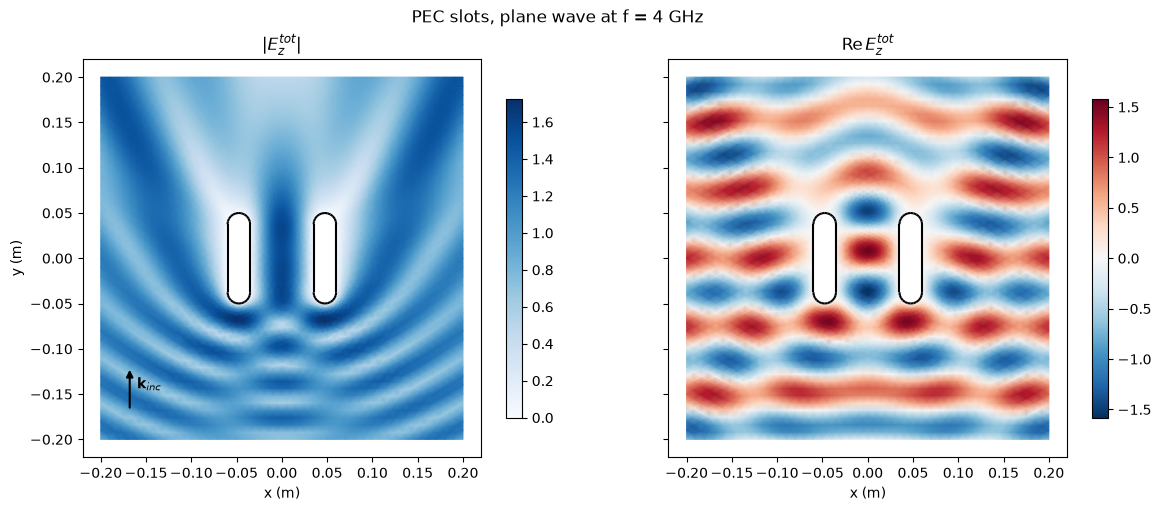

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.tri import Triangulation

tri = Triangulation(nodes.xy[:, 0], nodes.xy[:, 1], elements.node_idxs)
re_max = np.abs(Etot.real).max()  # symmetric limits so 0 sits at the neutral midpoint

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, layout="constrained")
panels = [
    (axes[0], np.abs(Etot), "Blues", dict(vmin=0), r"$|E_z^{tot}|$"),
    (
        axes[1],
        Etot.real,
        "RdBu_r",
        dict(vmin=-re_max, vmax=re_max),
        r"$\mathrm{Re}\,E_z^{tot}$",
    ),
]
for ax, field, cmap, lims, label in panels:
    im = ax.tripcolor(tri, field, shading="gouraud", cmap=cmap, **lims)
    # PEC outlines (the slots are holes in the mesh)
    ax.add_collection(LineCollection(xy, colors="black", linewidths=1.5))
    ax.set_aspect("equal")
    ax.set_xlabel("x (m)")
    ax.set_title(label)
    fig.colorbar(im, ax=ax, shrink=0.8)
axes[0].set_ylabel("y (m)")

# Direction of the incident plane wave
k_hat = KPW / np.linalg.norm(KPW)
x0, y0 = nodes.xy.min(axis=0)
span = np.ptp(nodes.xy, axis=0).min()
axes[0].annotate(
    "",
    xy=(
        x0 + 0.08 * span + 0.12 * span * k_hat[0],
        y0 + 0.08 * span + 0.12 * span * k_hat[1],
    ),
    xytext=(x0 + 0.08 * span, y0 + 0.08 * span),
    arrowprops=dict(arrowstyle="-|>", color="black", lw=1.5),
)
axes[0].text(x0 + 0.1 * span, y0 + 0.14 * span, r"$\mathbf{k}_{inc}$")

fig.suptitle(f"PEC slots, plane wave at f = {F_HZ / 1e9:.0f} GHz")
plt.show()